In [3]:
import pandas as pd

df = pd.read_csv("ai-impact-jobs-layoff-risk-dataset.csv")
df.head()

,Age,Education_Level,Years_of_Experience,Industry,Job_Role,Company_Size,Job_Level,Routine_Task_Percentage,Creativity_Requirement,Human_Interaction_Level,AI_Adoption_Level,Number_of_AI_Tools_Used,AI_Usage_Hours_Per_Week,Tasks_Automated_Percentage,AI_Training_Hours,Layoff_Risk
0,59,Master's,6,Finance,Accountant,Medium,Entry,84,21,94,Medium,5,7,40,26,High
1,44,Master's,14,Manufacturing,Production Supervisor,Small,Entry,30,84,68,Low,2,2,14,9,Low
2,36,Bachelor's,7,Retail,Store Manager,Medium,Senior,12,86,71,Low,0,1,6,3,Low
3,27,Bachelor's,6,Finance,Auditor,Large,Entry,90,18,21,Medium,3,10,67,26,High
4,49,High School,12,Finance,Auditor,Small,Entry,49,52,72,Medium,5,13,26,19,Medium


In [4]:
# Train a small Random Forest
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

X = df.drop(columns="Layoff_Risk")
y = df["Layoff_Risk"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

categorical_columns = X_train.select_dtypes(include=["object", "category"]).columns
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
    ],
    remainder="passthrough",
)
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

rf = RandomForestClassifier(
    n_estimators=50,
    max_depth=4,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

# Count actual nodes
nodes = [tree.tree_.node_count for tree in rf.estimators_]
leaves = [tree.get_n_leaves() for tree in rf.estimators_]

print("Number of trees:", len(nodes))
print("Total nodes:", sum(nodes))
print("Decision nodes:", sum(nodes) - sum(leaves))
print("Leaf nodes:", sum(leaves))
print("Average nodes per tree:", sum(nodes) / len(nodes))
print("Test accuracy:", round(rf.score(X_test, y_test), 4))


Number of trees: 50
Total nodes: 1550
Decision nodes: 750
Leaf nodes: 800
Average nodes per tree: 31.0
Test accuracy: 0.734


DATS 6103 | Six testable stories from AI-exposure data
Three tree/ensemble ideas and three multinomial logistic-regression ideas. The observations and risk categories are synthetic. None of these patterns establishes the actual layoff risk of real workers.

The CSV belongs in the same folder as this notebook. Run the cells in order. Outputs are saved to dats6103_six_story_figures/. Each idea generates a standalone PNG.

Model-validation rule: the code creates a stratified 80% development split and a 20% holdout. Everything below, including plots, model fitting, and 5-fold cross-validation, uses only the development split. The holdout is not used or scored.

In [7]:
import argparse
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.colors import Normalize
from matplotlib.ticker import PercentFormatter
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

SEED = 6103
LABELS = ["Low", "Medium", "High"]
COLORS = dict(zip(LABELS, ["#3283a8", "#e8ab48", "#b95346"]))
LINE_COLORS = ["#3283a8", "#e8ab48", "#b95346"]


def format_figure(fig, name, folder):
    fig.savefig(folder / name, dpi=190, bbox_inches="tight", facecolor="white")
    display(fig)
    plt.close(fig)


def add_subtitle(ax, note):
    ax.text(0.0, 1.035, note, transform=ax.transAxes, va="bottom", fontsize=10, color="#536272")


def build_pipeline(features, kind):
    categorical = [c for c in features if c in {"AI_Adoption_Level", "Industry", "Job_Level", "Company_Size", "Job_Role", "Education_Level"}]
    numeric = [c for c in features if c not in categorical]
    transformer = ColumnTransformer(
        [("num", StandardScaler() if kind == "logit" else "passthrough", numeric),
         ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical)],
        sparse_threshold=0,
    )
    if kind == "tree":
        est = DecisionTreeClassifier(max_depth=3, min_samples_leaf=180, random_state=SEED)
    elif kind == "forest":
        est = RandomForestClassifier(n_estimators=50, max_depth=4, min_samples_leaf=90,
                                     random_state=SEED, n_jobs=-1)
    elif kind == "logit":
        est = LogisticRegression(max_iter=2500, solver="lbfgs")
    else:
        raise ValueError(kind)
    return Pipeline([("prep", transformer), ("model", est)])


def validation_metrics(model, dev, features):
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    s = cross_validate(model, dev[features], dev["Layoff_Risk"], cv=cv,
                       scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"}, n_jobs=1)
    return {"CV accuracy": float(s["test_accuracy"].mean()),
            "CV macro F1": float(s["test_f1_macro"].mean()),
            "Fold F1 SD": float(s["test_f1_macro"].std(ddof=1))}


def risk_table(df, by):
    g = df.groupby(by, observed=True)["Layoff_Risk"]
    return pd.DataFrame({"n": g.size(), "high_rate": g.apply(lambda s: (s == "High").mean())})

In [8]:
#Data preparation and majority-class baseline
output_folder = Path("dats6103_six_story_figures")
output_folder.mkdir(parents=True, exist_ok=True)
if "df" not in globals() or not isinstance(df, pd.DataFrame):
    raise ValueError("Load your CSV into df first using pd.read_csv(...).")
required = {"Routine_Task_Percentage", "Tasks_Automated_Percentage", "Creativity_Requirement",
            "Human_Interaction_Level", "AI_Adoption_Level", "Number_of_AI_Tools_Used",
            "AI_Usage_Hours_Per_Week", "AI_Training_Hours", "Job_Level", "Layoff_Risk"}
if not required.issubset(df.columns):
    raise ValueError(f"Missing columns: {required - set(df.columns)}")

# IMPORTANT: split once and set aside the 20% holdout before exploring.
dev, holdout = train_test_split(df, test_size=0.2, random_state=SEED,
                                stratify=df["Layoff_Risk"])
# This check doesn't read the holdout labels for any evaluation.
majority_baseline = dev["Layoff_Risk"].value_counts(normalize=True).max()
print(f"Dataset: {len(df):,} rows, {len(df.columns)} cols. Dev: {len(dev):,}. Holdout: {len(holdout):,} (NOT evaluated).")
print(f"Majority baseline (dev): {majority_baseline:.1%}")
results = []
fitted = {}

def train_candidate(code, title, features, kind):
    model = build_pipeline(features, kind)
    result = validation_metrics(model, dev, features)
    model.fit(dev[features], dev["Layoff_Risk"])
    print(f"{code} {title}: accuracy={result['CV accuracy']:.3f}, macro F1={result['CV macro F1']:.3f}")
    results.append({"Idea": code, "Story": title, "Model": kind,
                    "Features": "; ".join(features), **result})
    fitted[code] = model
    return model

Dataset: 20,000 rows, 16 cols. Dev: 16,000. Holdout: 4,000 (NOT evaluated).
Majority baseline (dev): 34.0%


T1 · Routine tasks + automated tasks
How do correlated predictors become threshold rules? Visual: depth-3 decision tree. Use node sample shares and branch boundaries to build a narrative. We compare the tree using 5-fold cross-validation.

T1 Where do routine tasks become high risk?: accuracy=0.687, macro F1=0.686


<Figure size 1700x850 with 1 Axes>

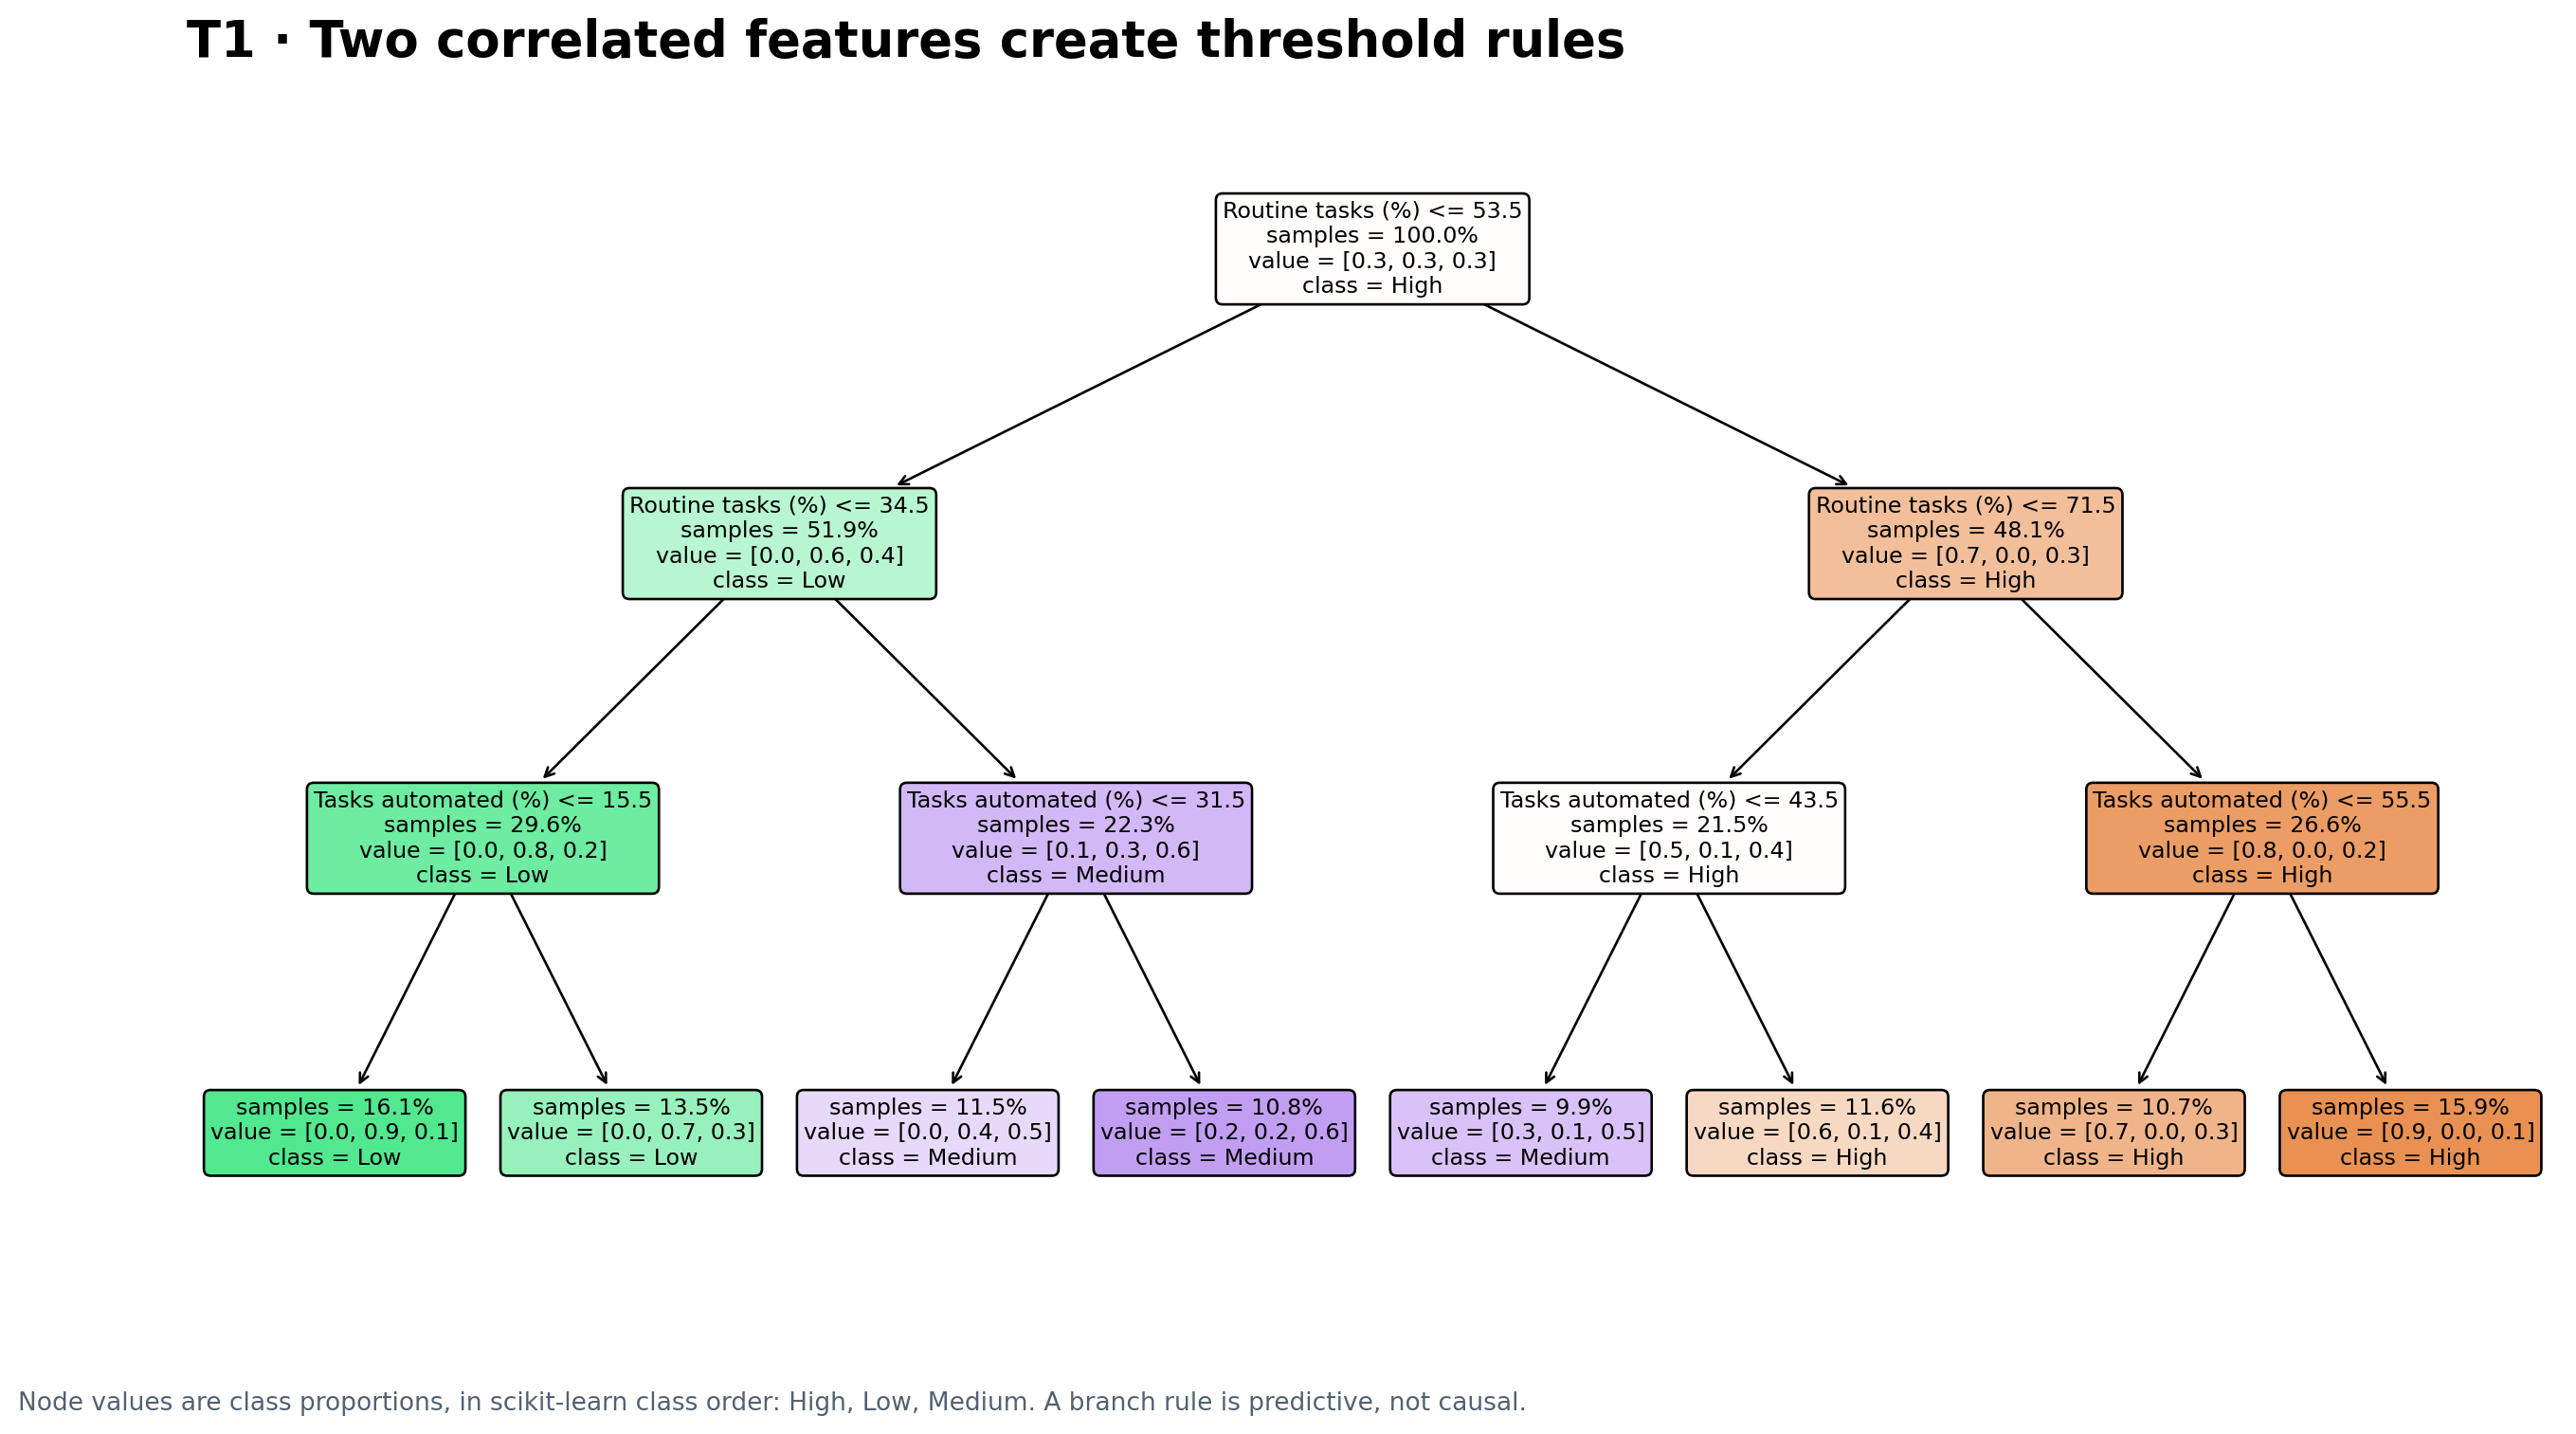

In [12]:
t1cols = ["Routine_Task_Percentage", "Tasks_Automated_Percentage"]
t1 = train_candidate("T1", "Where do routine tasks become high risk?", t1cols, "tree")
tree = t1.named_steps["model"]
fig, ax = plt.subplots(figsize=(17, 8.5))
plot_tree(tree, ax=ax, feature_names=["Routine tasks (%)", "Tasks automated (%)"],
          class_names=tree.classes_, filled=True, rounded=True, proportion=True,
          impurity=False, fontsize=9, precision=1)
ax.set_title("T1 · Two correlated features create threshold rules", fontsize=20, weight="bold", loc="left", pad=18)
fig.text(0.07, 0.025, "Node values are class proportions, in scikit-learn class order: High, Low, Medium. A branch rule is predictive, not causal.", fontsize=10, color="#526172")
format_figure(fig, "01_tree_thresholds.png", output_folder)

from IPython.display import display, Image
display(Image(filename=str(output_folder / "01_tree_thresholds.png"), width=900))

T2 · Automation + AI adoption + number of tools
Is High-risk prevalence different across combinations of automation and adoption? Visual: observed group means with n in every heatmap cell. Extremely small cells are descriptive only, not reliable comparisons.

T2 Does AI adoption modify automation risk?: accuracy=0.667, macro F1=0.656


<Figure size 1280x550 with 2 Axes>

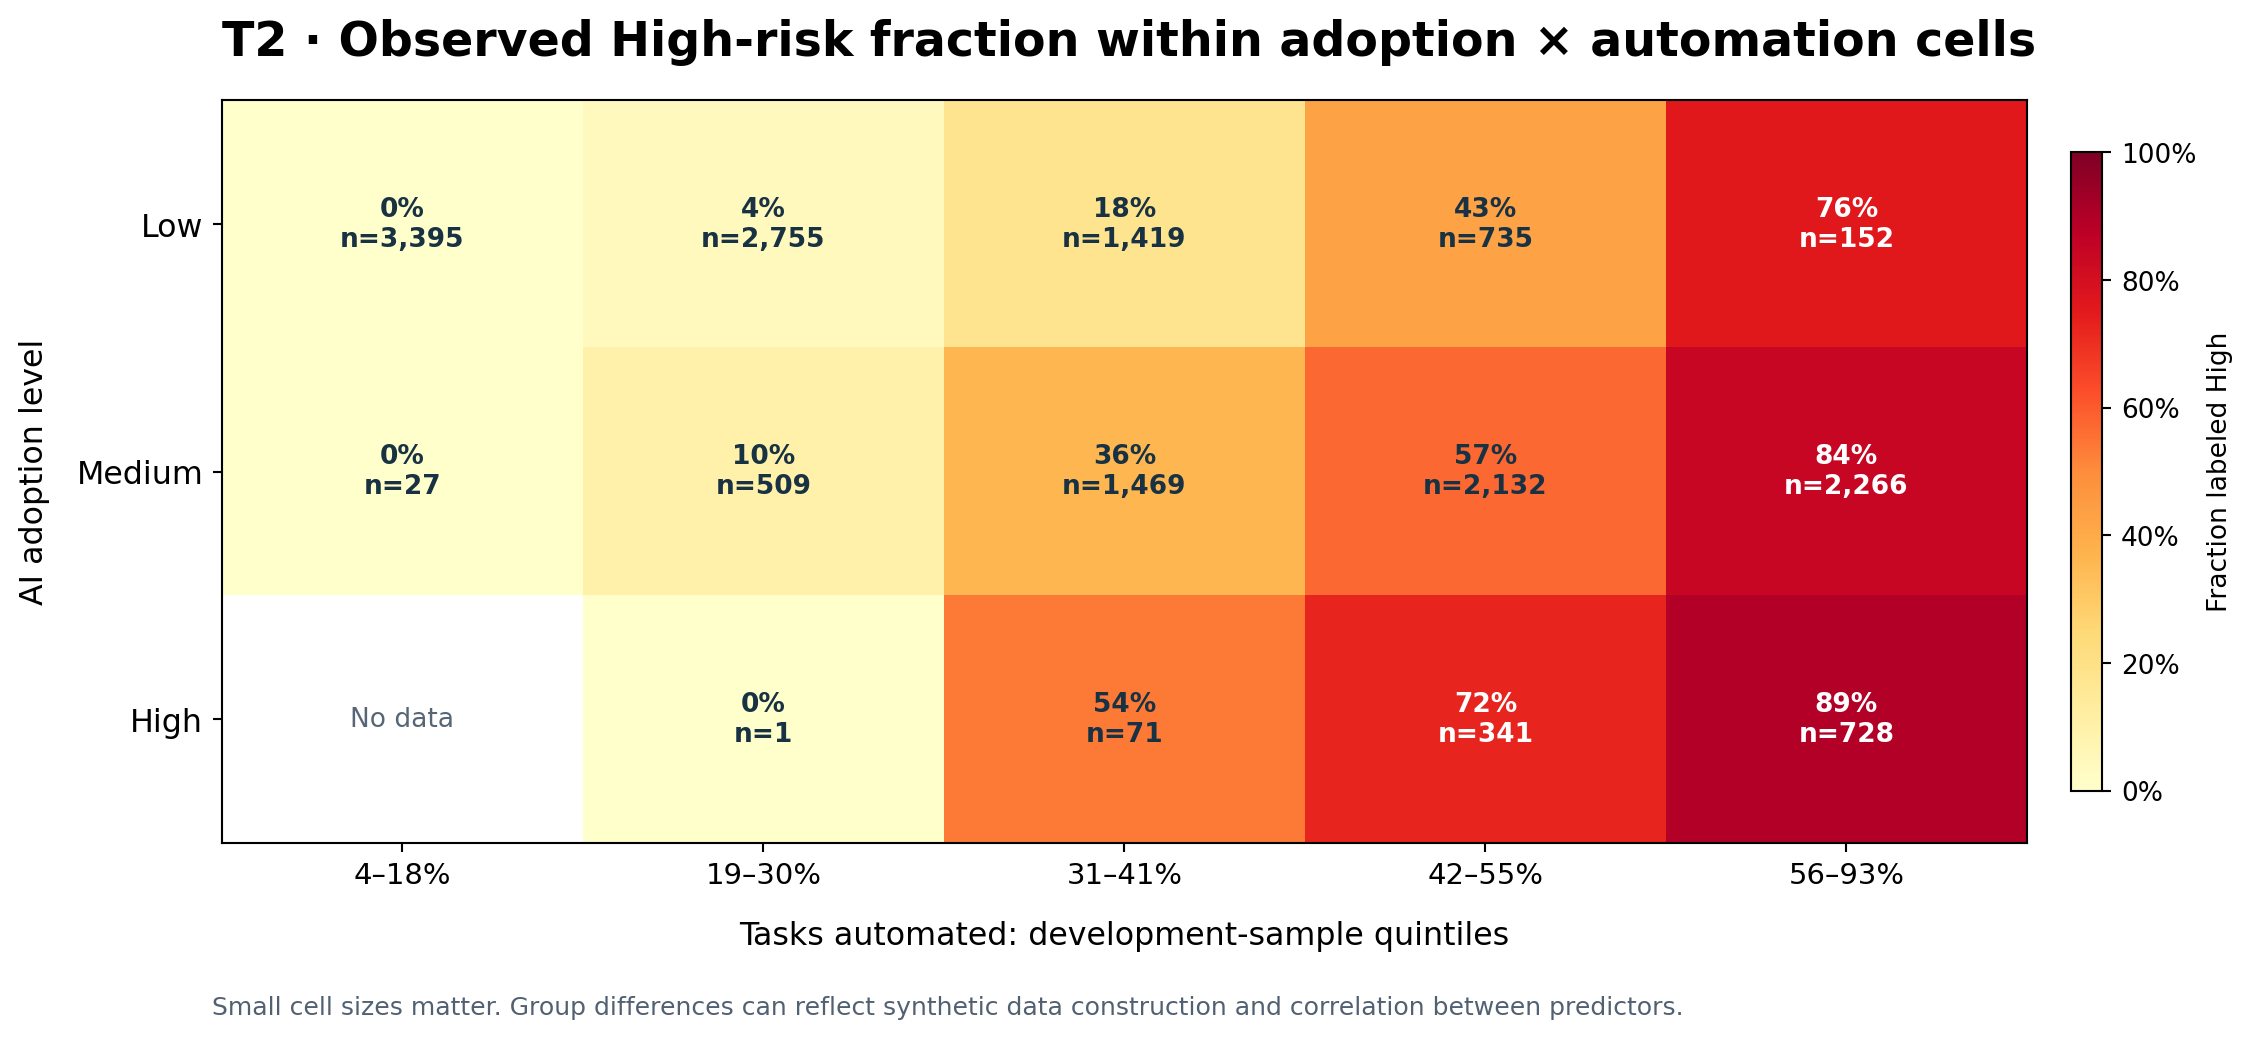

In [13]:
t2cols = ["Tasks_Automated_Percentage", "AI_Adoption_Level", "Number_of_AI_Tools_Used"]
t2 = train_candidate("T2", "Does AI adoption modify automation risk?", t2cols, "tree")
adoption_order = ["Low", "Medium", "High"]
bins = pd.qcut(dev["Tasks_Automated_Percentage"], q=5, duplicates="drop")
dist = dev.assign(Automation_Bin=bins).groupby(["AI_Adoption_Level", "Automation_Bin"], observed=False)
agg = dist["Layoff_Risk"].agg(n="size", high_rate=lambda s: (s == "High").mean()).reset_index()
agg["AI_Adoption_Level"] = pd.Categorical(agg["AI_Adoption_Level"], categories=adoption_order, ordered=True)
h = agg.pivot(index="AI_Adoption_Level", columns="Automation_Bin", values="high_rate").reindex(adoption_order)
counts = agg.pivot(index="AI_Adoption_Level", columns="Automation_Bin", values="n").reindex(adoption_order)
fig, ax = plt.subplots(figsize=(12.8, 5.5))
mesh = ax.imshow(h.values, vmin=0, vmax=1, aspect="auto", cmap="YlOrRd")
ax.set_xticks(np.arange(h.shape[1]), [f"{int(iv.left)+1}–{int(iv.right)}%" for iv in h.columns], fontsize=11)
ax.set_yticks(np.arange(3), adoption_order, fontsize=12)
for i in range(3):
    for j in range(h.shape[1]):
        v, n = h.iloc[i, j], counts.iloc[i, j]
        if not pd.isna(v) and int(n) > 0:
            ax.text(j, i, f"{v:.0%}\nn={int(n):,}", ha="center", va="center", fontsize=10,
                    color="white" if v > .59 else "#183244", weight="bold")
        else:
            ax.text(j, i, "No data", ha="center", va="center", color="#566677", fontsize=10)
ax.set_xlabel("Tasks automated: development-sample quintiles", fontsize=12, labelpad=12)
ax.set_ylabel("AI adoption level", fontsize=12, labelpad=10)
ax.set_title("T2 · Observed High-risk fraction within adoption × automation cells", fontsize=18, weight="bold", loc="left", pad=17)
cb = fig.colorbar(mesh, ax=ax, shrink=.86, pad=.02)
cb.set_label("Fraction labeled High")
cb.ax.yaxis.set_major_formatter(PercentFormatter(1))
fig.text(.09, .02, "Small cell sizes matter. Group differences can reflect synthetic data construction and correlation between predictors.", fontsize=9.5, color="#526172")
fig.tight_layout(rect=[0, .055, 1, 1])
format_figure(fig, "02_tree_adoption_automation.png", output_folder)

from IPython.display import display, Image
display(Image(filename=str(output_folder / "02_tree_adoption_automation.png"), width=900))

T3 · Creativity + human interaction + job level
Does a 50-tree random forest rely mainly on creativity or do job level and interaction add more? Visual: observed group averages and impurity-weighted model feature importance. Split importance is not causal importance.

T3 Creative, people-facing, senior jobs: accuracy=0.732, macro F1=0.726


<Figure size 1420x580 with 2 Axes>

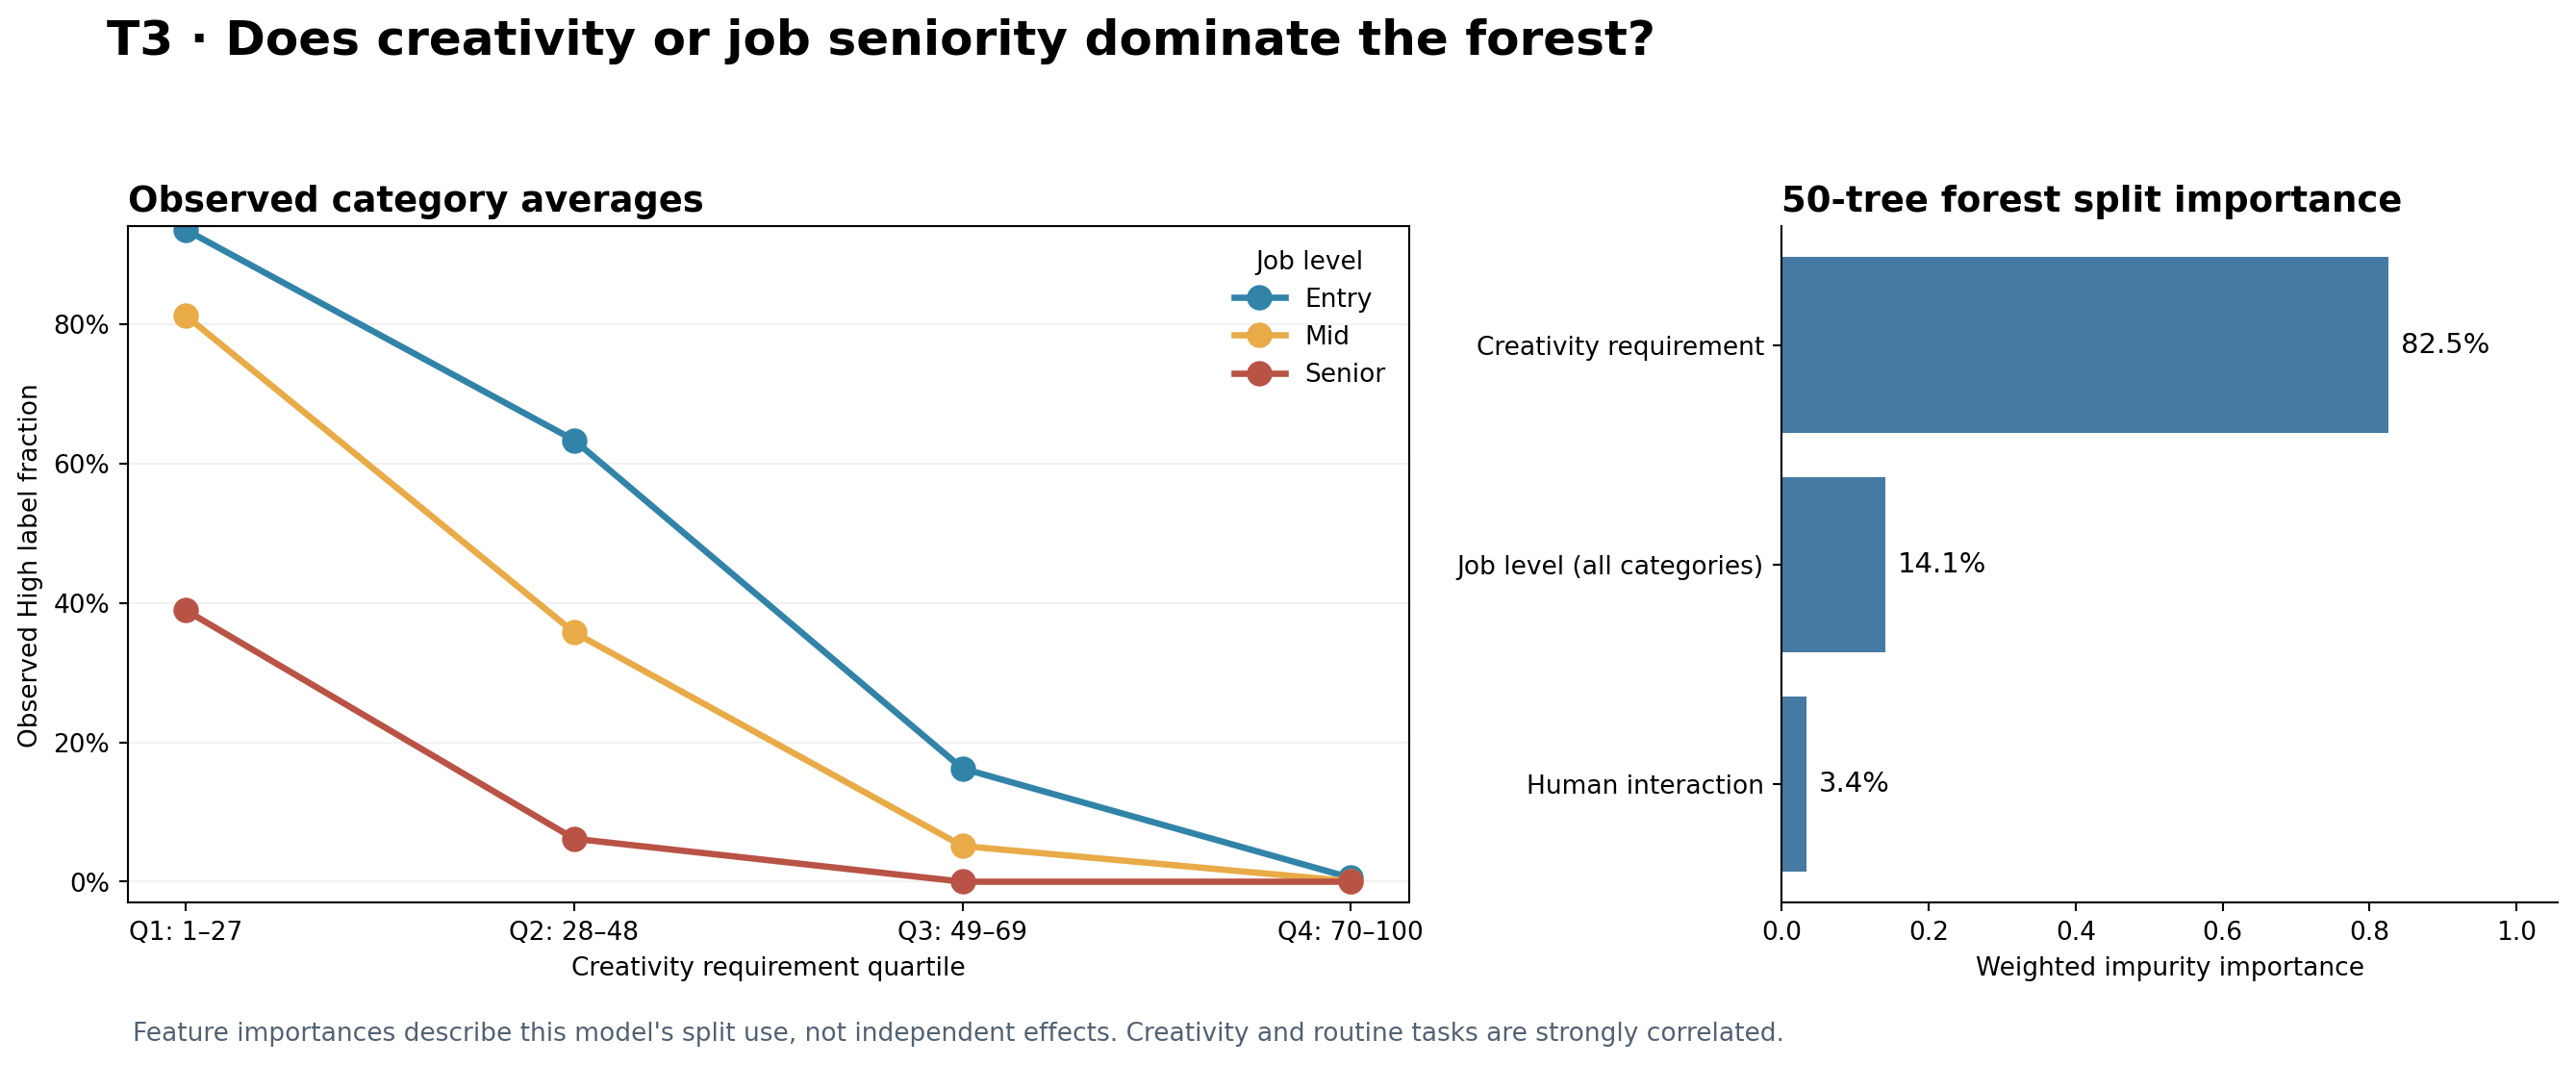

In [14]:
# prediction probabilities are averages across 50 trees.
t3cols = ["Creativity_Requirement", "Human_Interaction_Level", "Job_Level"]
t3 = train_candidate("T3", "Creative, people-facing, senior jobs", t3cols, "forest")
forest = t3.named_steps["model"]
names = t3.named_steps["prep"].get_feature_names_out()
weights = pd.Series(forest.feature_importances_, index=names)
weighted_importance = {
    "Creativity requirement": weights.filter(like="Creativity_Requirement").sum(),
    "Human interaction": weights.filter(like="Human_Interaction_Level").sum(),
    "Job level (all categories)": weights.filter(like="Job_Level_").sum(),
}
tmp = dev.copy()
tmp["Creativity quartile"] = pd.qcut(tmp["Creativity_Requirement"], 4, duplicates="drop")
tmp["Job_Level"] = pd.Categorical(tmp["Job_Level"], ["Entry", "Mid", "Senior"], ordered=True)
mean_risk = risk_table(tmp, ["Creativity quartile", "Job_Level"]).reset_index()
lines = mean_risk.pivot(index="Creativity quartile", columns="Job_Level", values="high_rate")
fig, axes = plt.subplots(1, 2, figsize=(14.2, 5.8), gridspec_kw={"width_ratios": [1.65, 1]})
for k, job in enumerate(["Entry", "Mid", "Senior"]):
    axes[0].plot(np.arange(len(lines)), lines[job], marker="o", markersize=9, lw=2.5,
                 label=job, color=LINE_COLORS[k])
axes[0].set_xticks(np.arange(len(lines)), [f"Q{i+1}: {int(b.left)+1}–{int(b.right)}" for i,b in enumerate(lines.index)])
axes[0].set_xlabel("Creativity requirement quartile")
axes[0].set_ylabel("Observed High label fraction")
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].set_ylim(-.03, .94)
axes[0].legend(title="Job level", frameon=False, loc="upper right")
axes[0].grid(axis="y", alpha=.17)
axes[0].set_title("Observed category averages", fontsize=14, weight="bold", loc="left")
imp = pd.Series(weighted_importance).sort_values()
bars = axes[1].barh(imp.index, imp.values, color="#467aa2")
axes[1].bar_label(bars, labels=[f"{x:.1%}" for x in imp.values], padding=5, fontsize=11)
axes[1].set_xlim(0, max(imp.values)*1.28)
axes[1].set_xlabel("Weighted impurity importance")
axes[1].set_title("50-tree forest split importance", fontsize=14, weight="bold", loc="left")
axes[1].spines[["top", "right"]].set_visible(False)
fig.suptitle("T3 · Does creativity or job seniority dominate the forest?", fontsize=19, weight="bold", x=.045, ha="left")
fig.text(.055, .015, "Feature importances describe this model's split use, not independent effects. Creativity and routine tasks are strongly correlated.", fontsize=10, color="#526172")
fig.tight_layout(rect=[0, .045, 1, .92])
format_figure(fig, "03_forest_creativity_seniority.png", output_folder)

from IPython.display import display, Image
display(Image(filename=str(output_folder / "03_forest_creativity_seniority.png"), width=900))

R1 · Routine + automation as a smooth gradient
Multinomial logistic regression learns a smooth probability surface rather than tree cutoffs. Visual: estimated P(High) alongside observed synthetic-profile coverage. Blank areas have low support.

R1 A smooth risk gradient rather than fixed thresholds: accuracy=0.696, macro F1=0.692


<Figure size 1140x700 with 2 Axes>

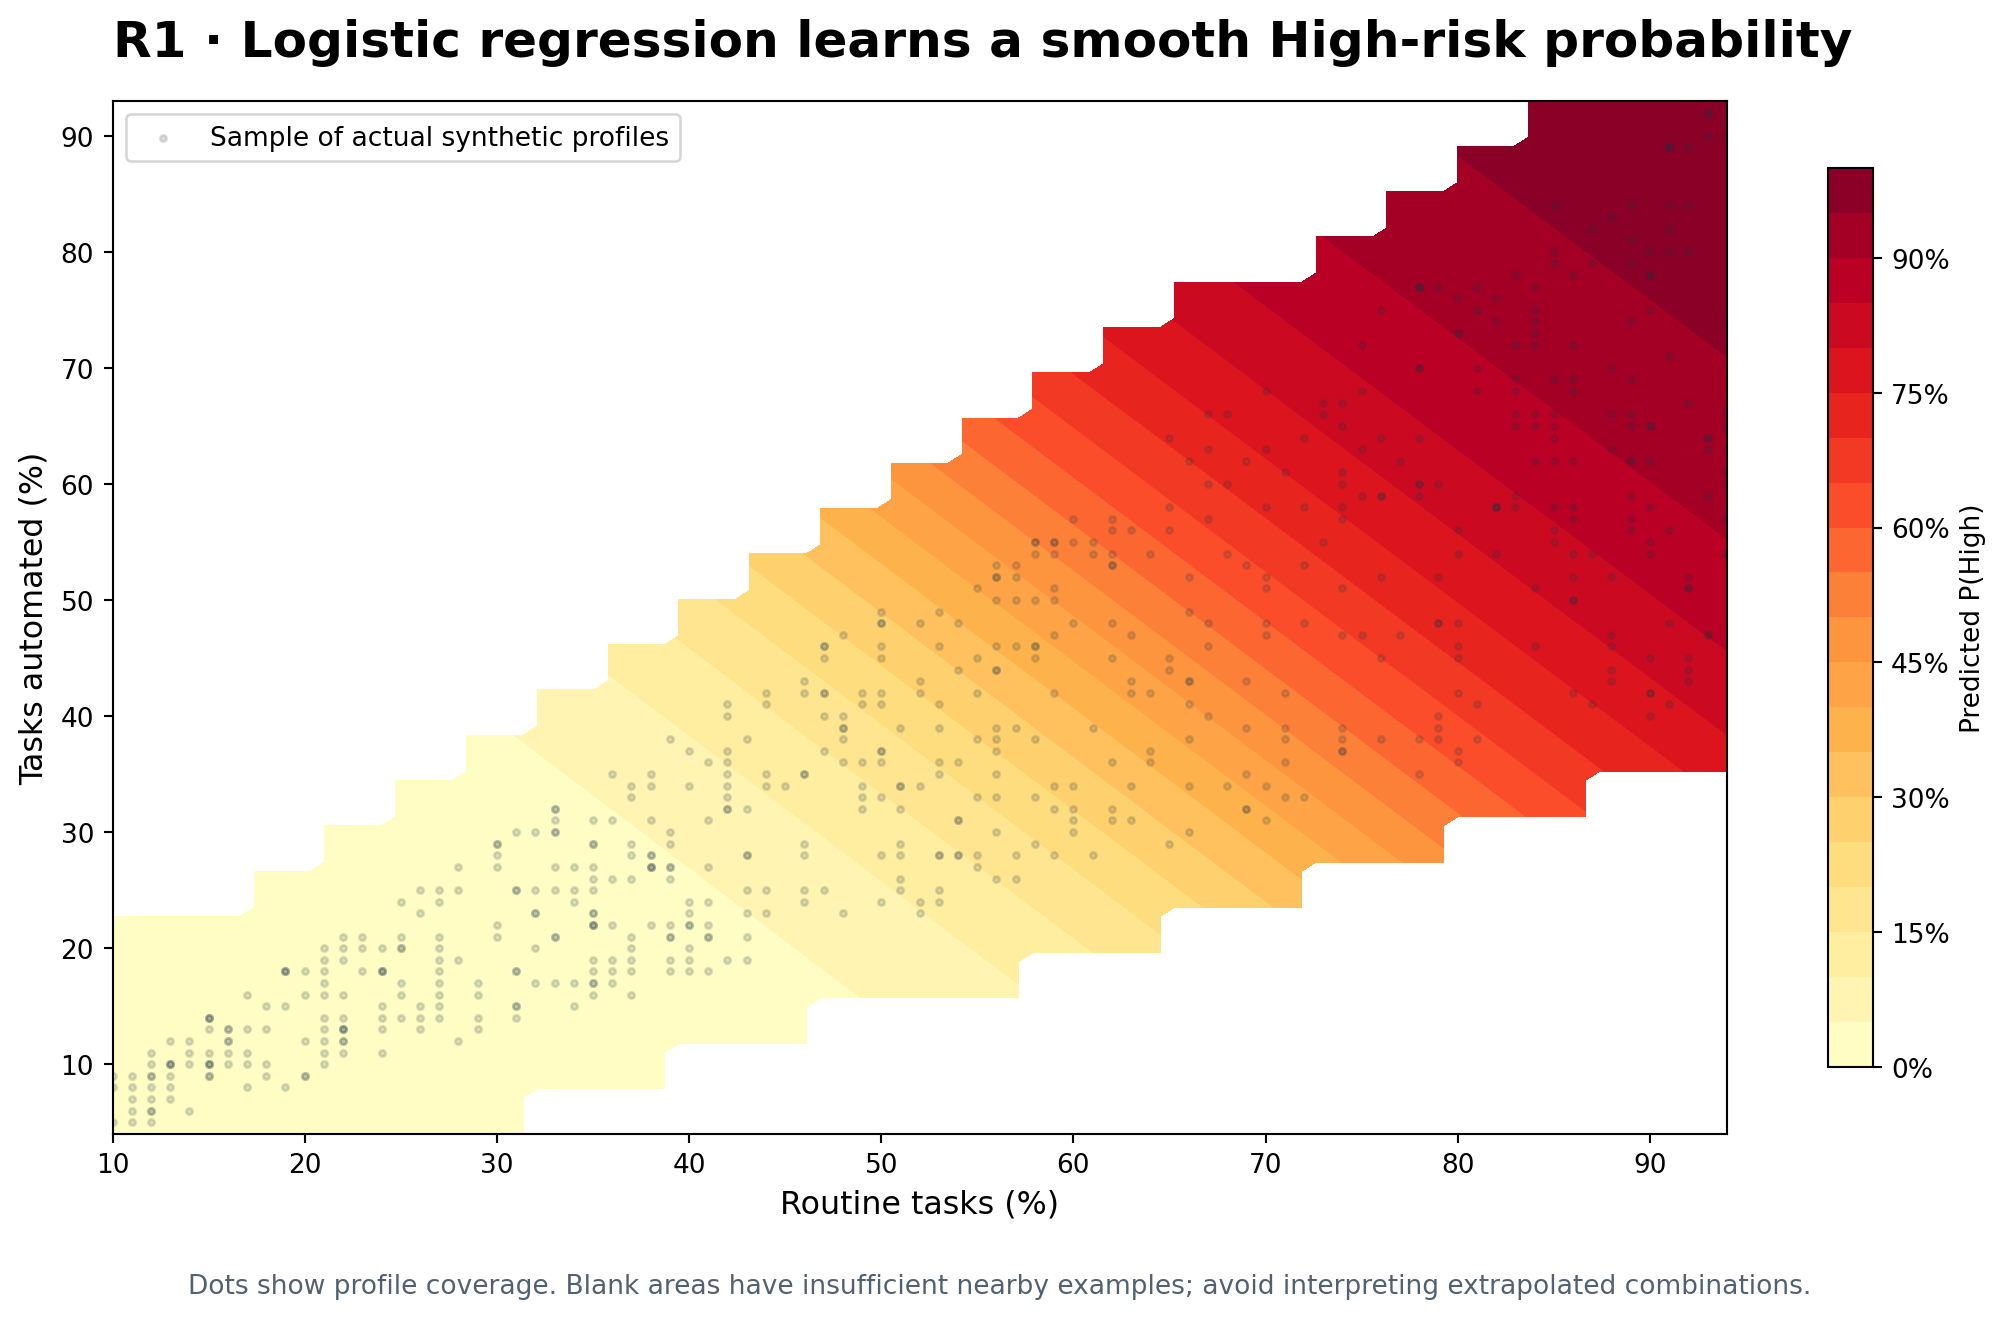

In [15]:
r1cols = ["Routine_Task_Percentage", "Tasks_Automated_Percentage"]
r1 = train_candidate("R1", "A smooth risk gradient rather than fixed thresholds", r1cols, "logit")
xv = np.linspace(dev[r1cols[0]].min(), dev[r1cols[0]].max(), 115)
yv = np.linspace(dev[r1cols[1]].min(), dev[r1cols[1]].max(), 115)
xx, yy = np.meshgrid(xv, yv)
grid = pd.DataFrame({r1cols[0]: xx.ravel(), r1cols[1]: yy.ravel()})
hi = list(r1.named_steps["model"].classes_).index("High")
zz = r1.predict_proba(grid)[:, hi].reshape(xx.shape)
# Mask extrapolated combinations: display only bins with empirical support in a
# nearby neighborhood in the development data.
hc, xe, ye = np.histogram2d(dev[r1cols[0]], dev[r1cols[1]], bins=[23, 23], range=[[xv.min(),xv.max()], [yv.min(),yv.max()]])
xi = np.clip(np.digitize(xx, xe)-1, 0, 22)
yi = np.clip(np.digitize(yy, ye)-1, 0, 22)
# 3×3 local counts, approximate support for smoothing over bin edges.
padded = np.pad(hc, 1)
local = sum(padded[a:a+23, b:b+23] for a in range(3) for b in range(3))
zz = np.ma.masked_where(local[xi, yi] < 8, zz)
fig, ax = plt.subplots(figsize=(11.4, 7))
cf = ax.contourf(xx, yy, zz, levels=np.linspace(0,1,21), cmap="YlOrRd", extend="neither")
rng = np.random.default_rng(SEED)
observed = dev.iloc[rng.choice(len(dev), size=650, replace=False)]
ax.scatter(observed[r1cols[0]], observed[r1cols[1]], s=6, alpha=.15, color="#193344", label="Sample of actual synthetic profiles")
ax.set_xlabel("Routine tasks (%)", fontsize=12)
ax.set_ylabel("Tasks automated (%)", fontsize=12)
ax.set_title("R1 · Logistic regression learns a smooth High-risk probability", fontsize=19, weight="bold", loc="left", pad=17)
ax.legend(loc="upper left", frameon=True)
cb = fig.colorbar(cf, ax=ax, shrink=.87)
cb.set_label("Predicted P(High)")
cb.ax.yaxis.set_major_formatter(PercentFormatter(1))
fig.text(.09, .02, "Dots show profile coverage. Blank areas have insufficient nearby examples; avoid interpreting extrapolated combinations.", fontsize=10, color="#526172")
fig.tight_layout(rect=[0, .055, 1, 1])
format_figure(fig, "04_regression_risk_surface.png", output_folder)

from IPython.display import display, Image
display(Image(filename=str(output_folder / "04_regression_risk_surface.png"), width=900))

R2 · Tools + usage + training as a weighted log-odds score
Contrast empirical training-hour quartile means with standardized coefficients for log[P(High)/P(Low)]. The model uses a weighted linear score and softmax, not a weighted arithmetic average of risks.

R2 Tools, usage, and training: correlated exposure: accuracy=0.561, macro F1=0.504


<Figure size 1470x540 with 2 Axes>

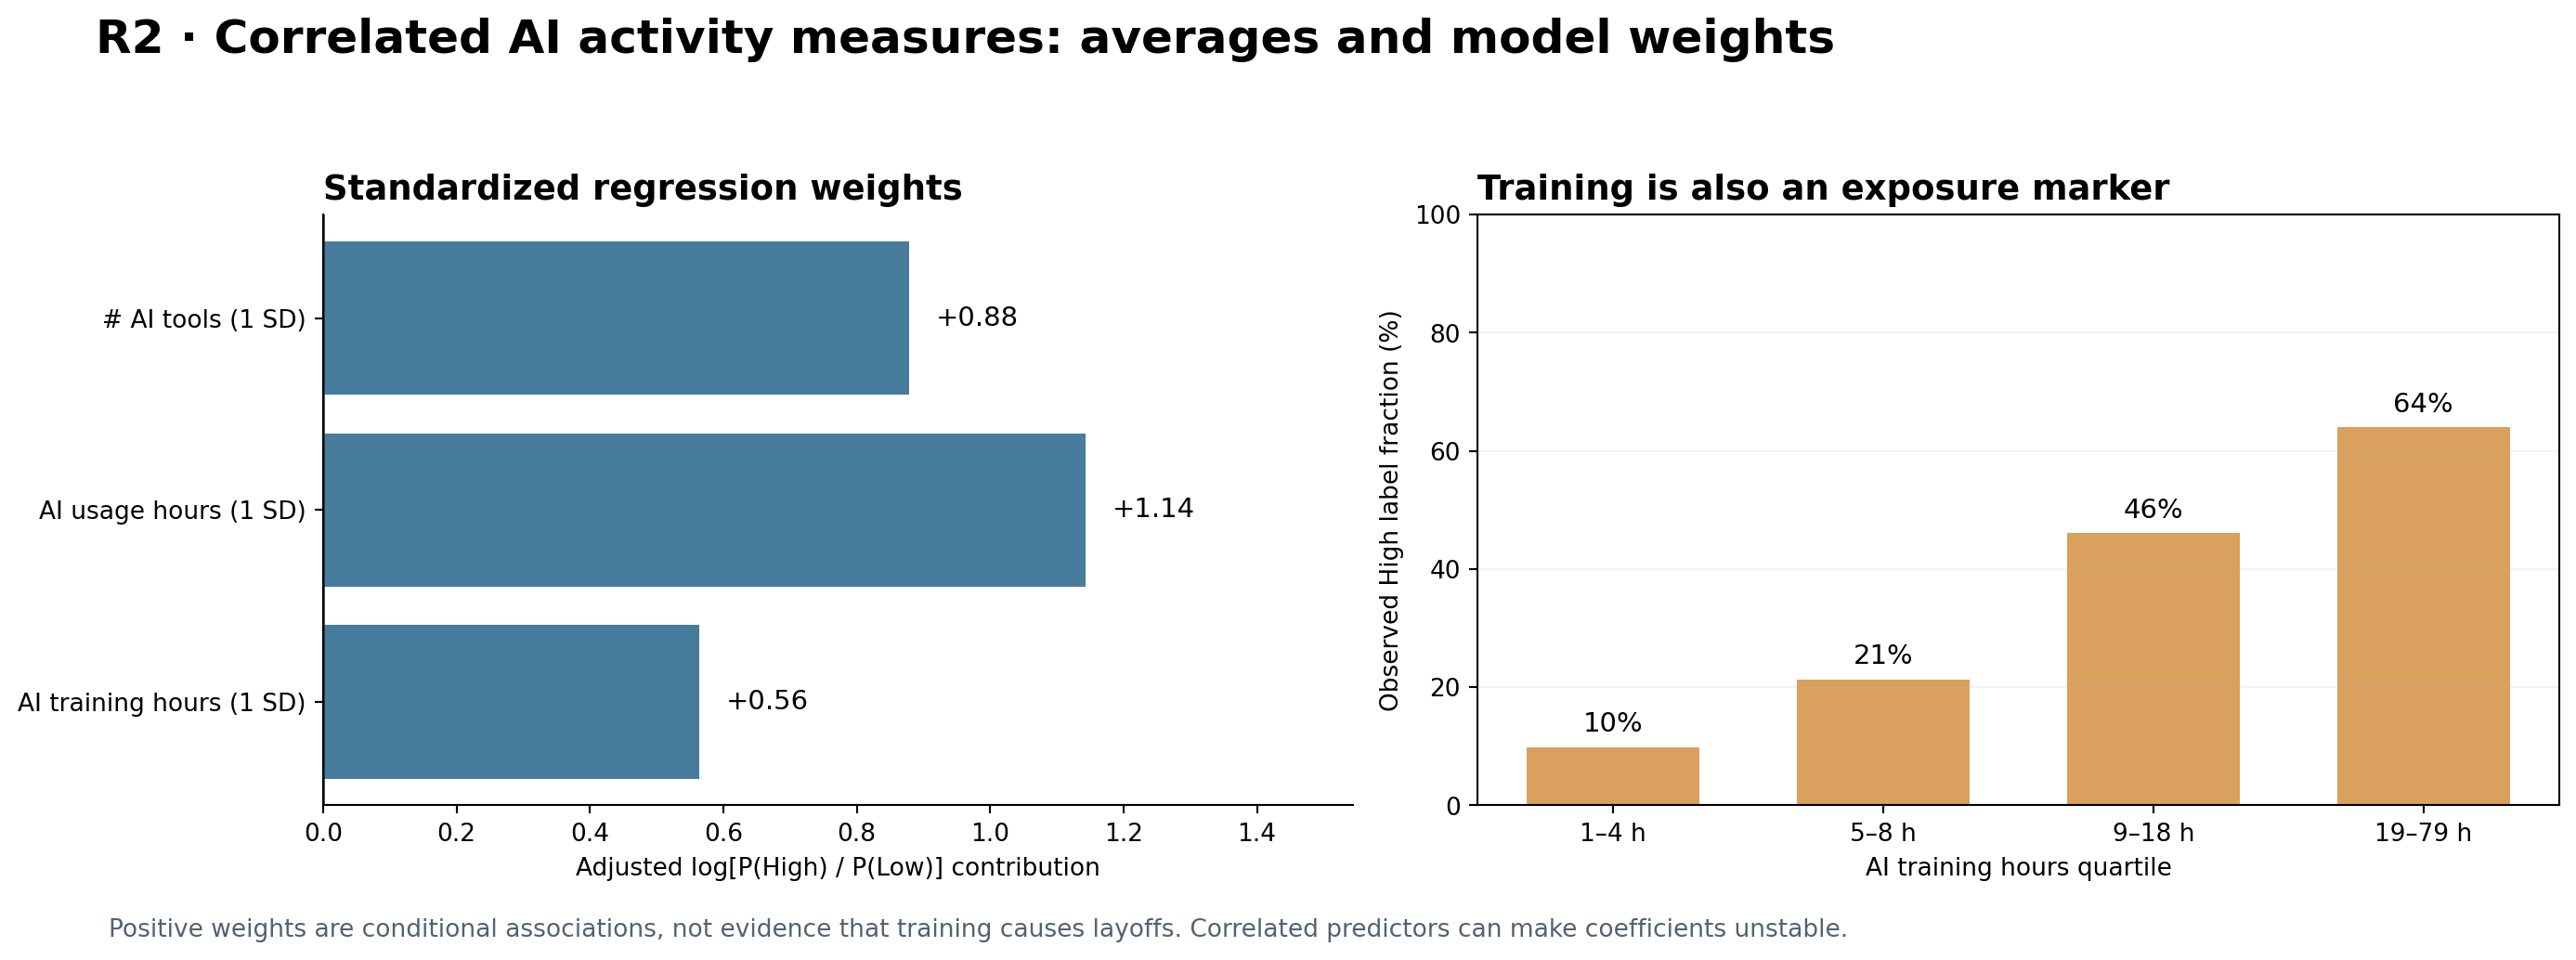

In [16]:
r2cols = ["Number_of_AI_Tools_Used", "AI_Usage_Hours_Per_Week", "AI_Training_Hours"]
r2 = train_candidate("R2", "Tools, usage, and training: correlated exposure", r2cols, "logit")
classes = list(r2.named_steps["model"].classes_)
coef = r2.named_steps["model"].coef_[classes.index("High")] - r2.named_steps["model"].coef_[classes.index("Low")]
values = pd.Series(coef, index=["# AI tools (1 SD)", "AI usage hours (1 SD)", "AI training hours (1 SD)"])
training_bands = pd.qcut(dev["AI_Training_Hours"], 4, duplicates="drop")
tr = risk_table(dev.assign(TrainingBand=training_bands), ["TrainingBand"]).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(14.7, 5.4), gridspec_kw={"width_ratios": [1, 1.05]})
bars = axes[0].barh(values.index[::-1], values.values[::-1], color="#477c9d")
axes[0].axvline(0, color="#28394a", lw=1)
for b in bars:
    axes[0].text(b.get_width() + .04, b.get_y()+b.get_height()/2, f"{b.get_width():+.2f}", va="center", fontsize=11)
axes[0].set_xlabel("Adjusted log[P(High) / P(Low)] contribution")
axes[0].set_title("Standardized regression weights", fontsize=14, weight="bold", loc="left")
axes[0].set_xlim(min(0, values.min()-.1), max(values)*1.35)
axes[0].spines[["right", "top"]].set_visible(False)
barx = axes[1].bar(range(len(tr)), tr.high_rate*100, color="#d9a15d", width=.64)
axes[1].bar_label(barx, labels=[f"{v:.0%}" for v in tr.high_rate], padding=4, fontsize=11)
axes[1].set_xticks(range(len(tr)), [f"{int(b.left)+1}–{int(b.right)} h" for b in tr.TrainingBand])
axes[1].set_ylim(0, 100)
axes[1].set_ylabel("Observed High label fraction (%)")
axes[1].set_xlabel("AI training hours quartile")
axes[1].set_title("Training is also an exposure marker", fontsize=14, weight="bold", loc="left")
axes[1].grid(axis="y", alpha=.16)
fig.suptitle("R2 · Correlated AI activity measures: averages and model weights", fontsize=19, weight="bold", x=.04, ha="left")
fig.text(.045, .015, "Positive weights are conditional associations, not evidence that training causes layoffs. Correlated predictors can make coefficients unstable.", fontsize=10, color="#526172")
fig.tight_layout(rect=[0, .045, 1, .92])
format_figure(fig, "05_regression_weights_training.png", output_folder)

from IPython.display import display, Image
display(Image(filename=str(output_folder / "05_regression_weights_training.png"), width=900))

R3 · Automation + human interaction + job level
Visual: probability curves by job seniority, with sensitivity bands from P10 to P90 of human-interaction levels. These bands are not confidence intervals.

R3 Seniority shifts the automation risk curve: accuracy=0.740, macro F1=0.740


<Figure size 1250x700 with 1 Axes>

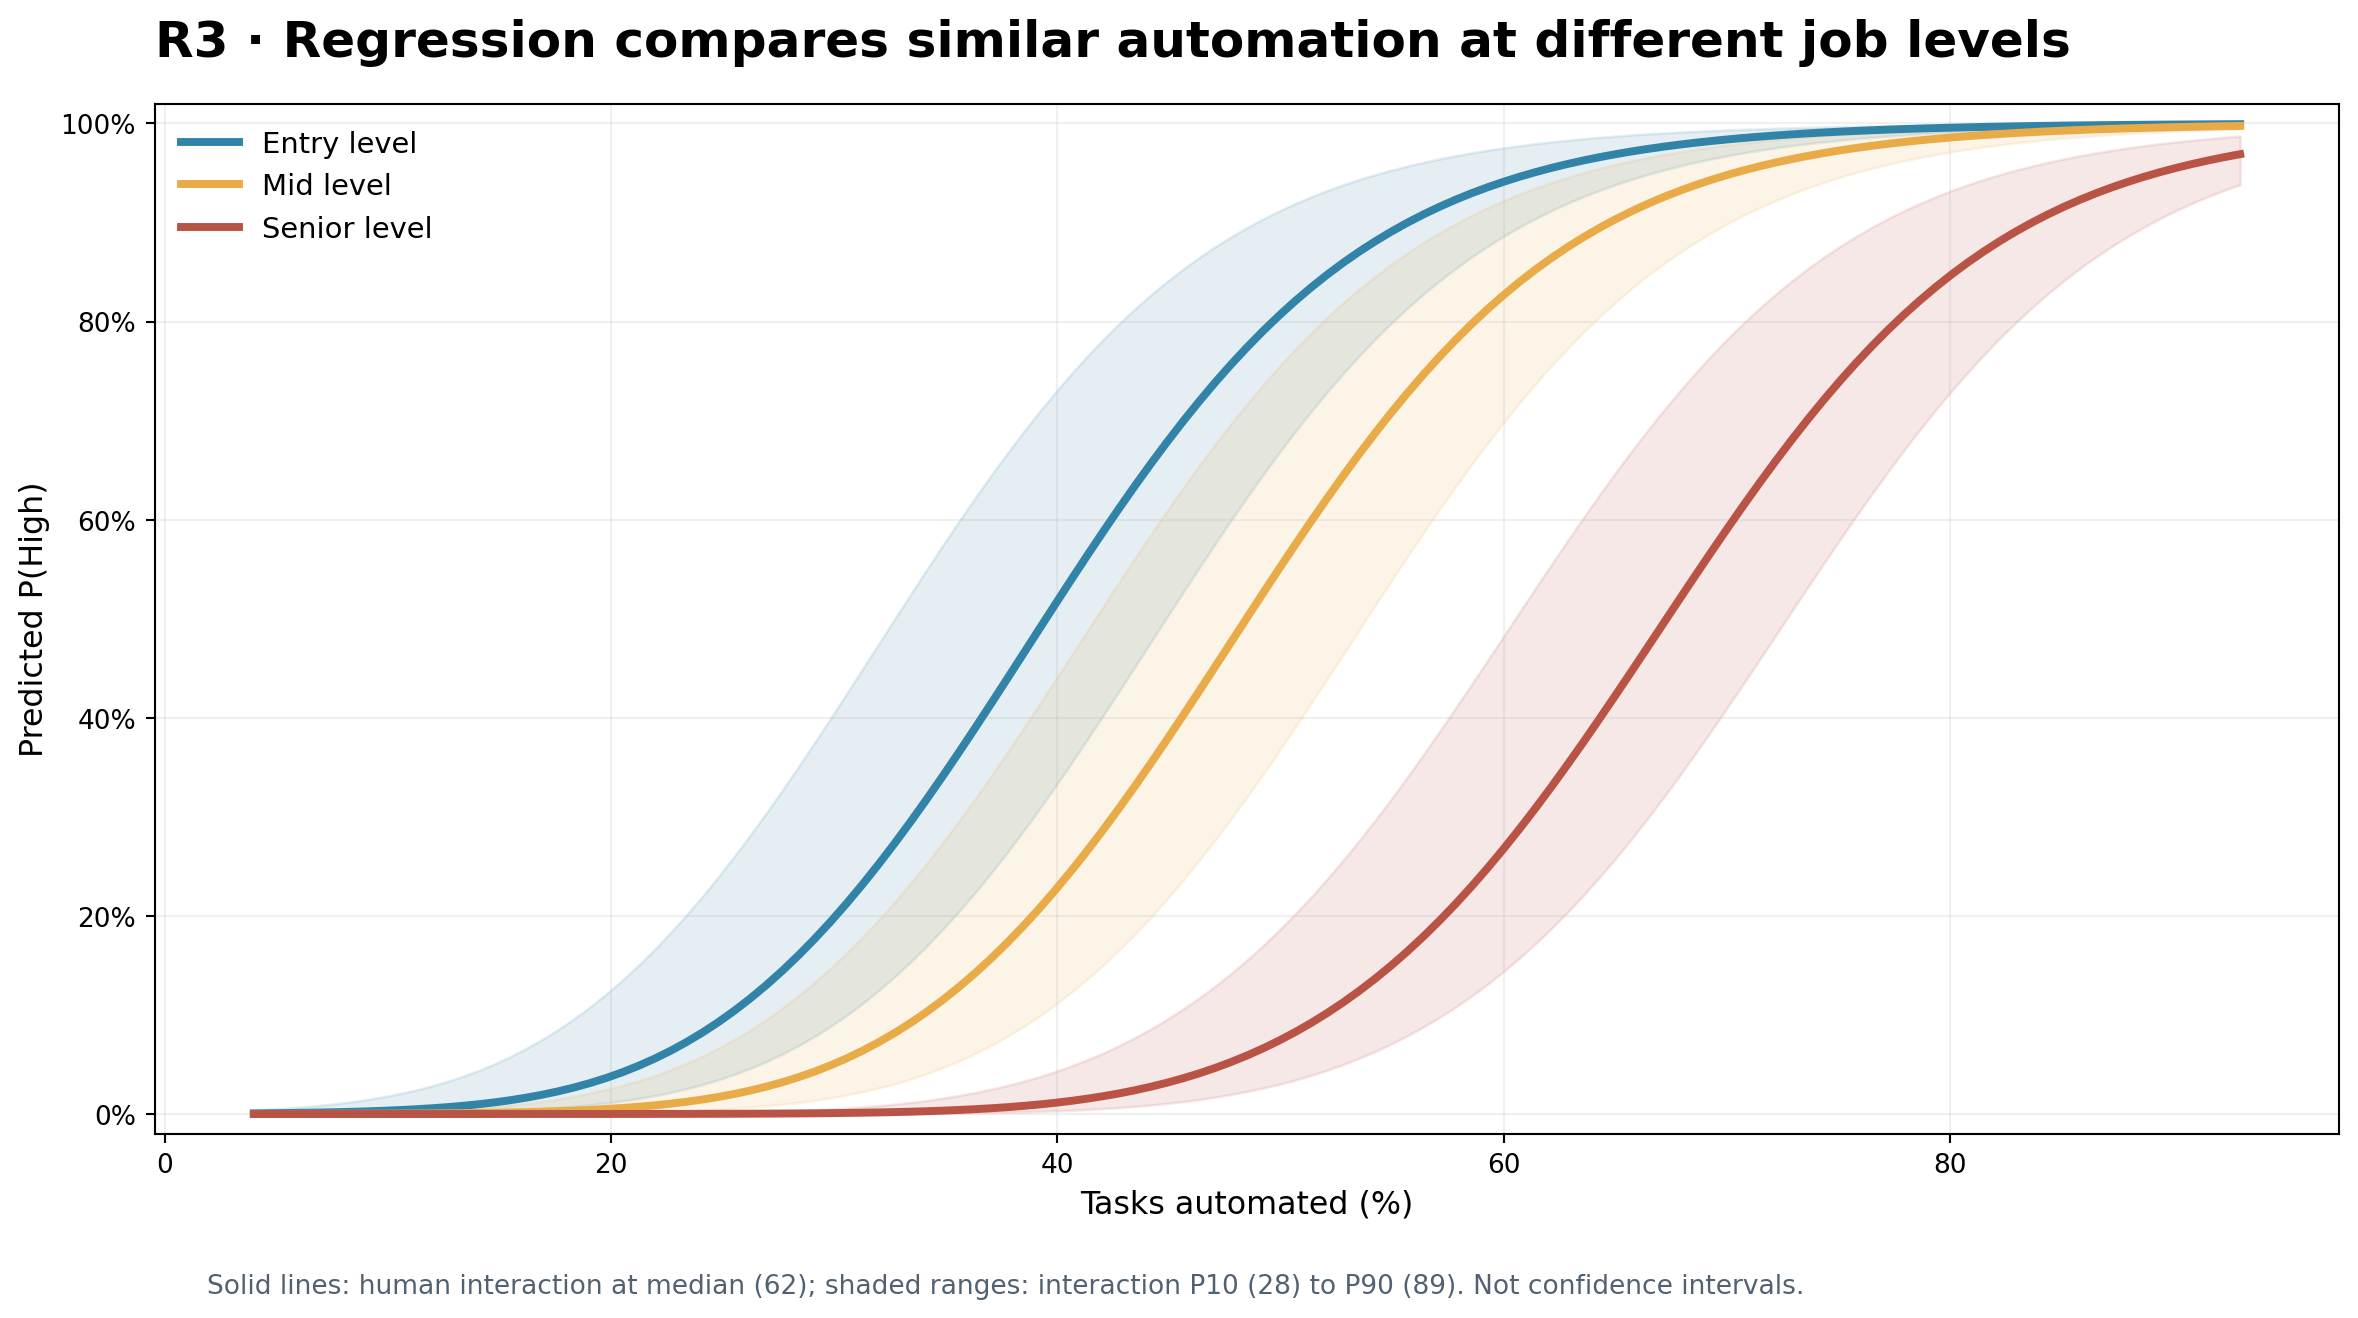

In [17]:
# sensitivity bands (P10 to P90), alongside a median scenario.
r3cols = ["Tasks_Automated_Percentage", "Human_Interaction_Level", "Job_Level"]
r3 = train_candidate("R3", "Seniority shifts the automation risk curve", r3cols, "logit")
a = np.linspace(float(dev["Tasks_Automated_Percentage"].min()),
                float(dev["Tasks_Automated_Percentage"].max()), 125)
humans = np.percentile(dev["Human_Interaction_Level"], [10, 50, 90])
fig, ax = plt.subplots(figsize=(12.5, 7))
for ix, job in enumerate(["Entry", "Mid", "Senior"]):
    probs = []
    for interaction in humans:
        pred = pd.DataFrame({"Tasks_Automated_Percentage":a,
                             "Human_Interaction_Level": float(interaction),
                             "Job_Level": job})
        probs.append(r3.predict_proba(pred)[:, list(r3.named_steps["model"].classes_).index("High")])
    ax.fill_between(a, np.minimum(probs[0], probs[2]), np.maximum(probs[0], probs[2]),
                    color=LINE_COLORS[ix], alpha=.13)
    ax.plot(a, probs[1], label=f"{job} level", color=LINE_COLORS[ix], lw=3)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylim(-.02, 1.02)
ax.set_xlabel("Tasks automated (%)", fontsize=12)
ax.set_ylabel("Predicted P(High)", fontsize=12)
ax.set_title("R3 · Regression compares similar automation at different job levels", fontsize=19, weight="bold", loc="left", pad=18)
ax.legend(frameon=False, loc="upper left", fontsize=11)
ax.grid(alpha=.18)
fig.text(.09, .02, f"Solid lines: human interaction at median ({humans[1]:.0f}); shaded ranges: interaction P10 ({humans[0]:.0f}) to P90 ({humans[2]:.0f}). Not confidence intervals.", fontsize=10, color="#526172")
fig.tight_layout(rect=[0, .055, 1, 1])
format_figure(fig, "06_regression_seniority_interaction.png", output_folder)

from IPython.display import display, Image
display(Image(filename=str(output_folder / "06_regression_seniority_interaction.png"), width=900))

Development-only results and export
Compare candidate 5-fold accuracy and macro F1. No test accuracy or confusion matrix is computed here; that belongs to a final locked model evaluation.

In [18]:
scores = pd.DataFrame(results)
scores.to_csv(output_folder / "candidate_cv_scores.csv", index=False)
desc = dev.groupby("Layoff_Risk")[["Routine_Task_Percentage", "Tasks_Automated_Percentage",
                                    "Creativity_Requirement", "Human_Interaction_Level",
                                    "Number_of_AI_Tools_Used", "AI_Usage_Hours_Per_Week",
                                    "AI_Training_Hours"]].agg(["mean", "min", "max"])
desc.to_csv(output_folder / "label_feature_min_mean_max.csv")
correlations = dev.select_dtypes("number").corr(method="spearman")
correlations.to_csv(output_folder / "development_spearman_correlations.csv")

# Create a contact sheet for quick discussion, preserving standalone exports.
from PIL import Image, ImageOps, ImageDraw, ImageFont
files = [output_folder / f"{i:02d}_{tail}.png" for i, tail in [
    (1, "tree_thresholds"), (2, "tree_adoption_automation"),
    (3, "forest_creativity_seniority"), (4, "regression_risk_surface"),
    (5, "regression_weights_training"), (6, "regression_seniority_interaction")]]
W, H, margin, top = 1200, 710, 50, 110
page = Image.new("RGB", (W*2+margin*3, H*3+margin*4+top), "#f4f6f8")
draw = ImageDraw.Draw(page)
try:
    font = ImageFont.truetype("/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf", 38)
except OSError:
    font = ImageFont.load_default()
draw.text((margin, 25), "SIX TESTABLE STORIES | DATS 6103", fill="#213649", font=font)
for i, p in enumerate(files):
    img = Image.open(p).convert("RGB")
    thumb = ImageOps.contain(img, (W, H-20))
    tile = Image.new("RGB", (W, H), "white")
    tile.paste(thumb, ((W-thumb.width)//2, (H-thumb.height)//2))
    x = margin+(i%2)*(W+margin)
    y = top+margin+(i//2)*(H+margin)
    page.paste(tile, (x, y))
page.save(output_folder / "six_ideas_storyboard.png", optimize=True)
print("\nDevelopment-only 5-fold CV scores:")
print(scores[["Idea", "Model", "CV accuracy", "CV macro F1"]].round(3).to_string(index=False))
print(f"\nExports: {output_folder.resolve()}")


Development-only 5-fold CV scores:
Idea  Model  CV accuracy  CV macro F1
  T1   tree        0.687        0.686
  T1   tree        0.687        0.686
  T1   tree        0.687        0.686
  T1   tree        0.687        0.686
  T2   tree        0.667        0.656
  T3 forest        0.732        0.726
  R1  logit        0.696        0.692
  R2  logit        0.561        0.504
  R3  logit        0.740        0.740

Exports: C:\Users\User\Dropbox\PC\Documents\GitHub\DATS6103_PROJECT\dats6103_six_story_figures


AI LOG:

1. Create 6 ideas of combinations of nodes to share and disscuss before implementing. Share with me a visual idea. We need to build the storytelling of the data to be able to build the model. (Each idea based on correlated, average, max and mins, weighted average) for trees and regression. (Meaning it has 3 ideas each totaling 6).


Ideas Processed: Build general to categories.

1. Build Automation + human interaction + seniority : "Broad correlation by each Rest of the categories (by industry, by ,.....)"
    
Feature relationship	Spearman correlation
Routine tasks ↔ Creativity	−0.932
Routine tasks ↔ Tasks automated	+0.910
AI tools used ↔ AI usage hours	+0.743
AI usage hours ↔ Training hours	+0.720